# 4.2 Beam B: three-span continuous flanged beam

Full design: loads → analysis (moment distribution) → envelope → bending → shear → flange shear → deflection → cracking → anchorage and curtailment → drawing.

| Step | Check | Reference |
|:--|:--|:--|
| 1 | Loads and load arrangements | EN 1990, NA 5.1.3 |
| 2 | Elastic analysis and envelope | EC2 5.4 |
| 3 | Cover, effective depth, fire | EC2 4.4.1, EN 1992-1-2 |
| 4 | Bending: spans (T-section), supports (rectangular) | EC2 5.3.2.1, 6.1 |
| 5 | Shear links; web–flange shear | EC2 6.2.3, 6.2.4, 9.2.2 |
| 6 | Deflection, cracking | EC2 7.4.2, 7.3 |
| 7 | Anchorage, laps, curtailment | EC2 8.4, 8.7, 9.2.1 |

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

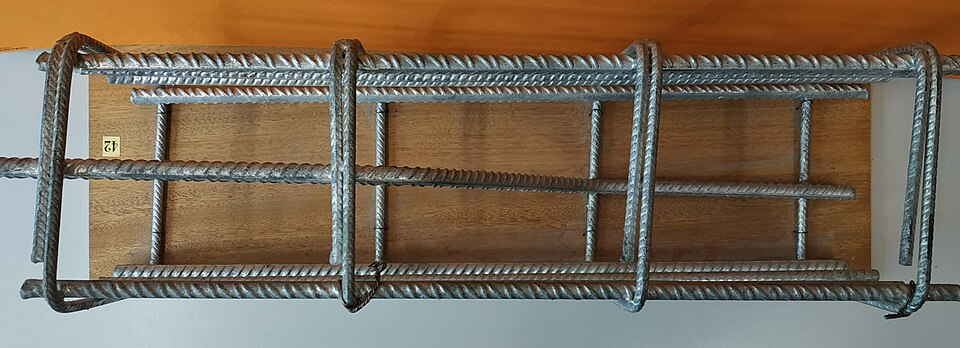

*Beam (lintel) cage seen from above: longitudinal bars held by closed links.* <br><small>Photo: Patrick Oberdörfer, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Bewehrungskorb_Sturz_oben.jpg).</small>

In [2]:
photo("beam_cage_2", "Beam (lintel) cage seen from above: longitudinal bars held by closed links.")

## 1. Loads and analysis

Arrangements, UK NA to 5.1.3 option (b): (1) all spans loaded; (2) alternate spans loaded. The same γ<sub>G</sub> is used throughout. Supports give no rotational restraint (EC2 5.3.2.2(2)).

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `phi`, `link`, `legs` | Main bar, link, number of link legs | mm | 8, 10, 12, 16, 20, 25, 32 |
| `n_AB`, `n_BC` | Bottom bars in the end and interior spans |  | 2 or more |
| `n_B`, `n_A` | Top bars at supports B and A |  | 2 or more |
| `n_run` | Bars running the full length, top and bottom |  | not more than any number above (**not checked**) |
| `s_near`, `s_else` | Link spacing near interior supports, and elsewhere | mm | > 0 |
| `leg` | Bend leg at support A | mm | > 0 |
| `lap_pct` | Bars lapped at one section | % | 1 to 100 |
| `slab_top`, `slab_bot` | Slab bars over the beam | mm | `(bar, spacing)`, match 3.3 |

Geometry, loads and materials come from `BRIEF`: see the guide in Notebook 0.1.

In [3]:
# INPUTS: edit only this cell, then run the cells below it
# Geometry, loads and materials come from BRIEF in ec2/project.py
phi, link, legs = 20, 8, 2                   # main bar (mm), link (mm), link legs
n_AB, n_BC, n_B, n_A = 4, 2, 4, 3            # bars: end span, interior span, support B, support A
n_run = 2                                    # bars running the full length, top and bottom (<= every number above)
s_near, s_else = 200, 300                    # link spacing near interior supports, elsewhere (mm)
leg, lap_pct = 200, 50                       # bend leg at support A (mm), bars lapped at one section (%)
slab_top, slab_bot = (10, 200), (10, 250)    # slab bars over Beam B (Notebook 3.3)

**Arrangement: All spans**

**Moment distribution (kN·m, counter-clockwise positive)**

| Step | AB | BA | BC | CB | CD | DC |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| Distribution factor | – | 0.429 | 0.571 | 0.571 | 0.429 | – |
| FEM | 176.21 | -176.21 | 165.00 | -165.00 | 176.21 | -176.21 |
| Release hinged end | -176.21 |  |  |  |  | 176.21 |
| Carry-over |  | -88.11 |  |  | 88.11 |  |
| Balance |  | 42.57 | 56.75 | -56.75 | -42.57 |  |
| Carry-over |  |  | -28.38 | 28.38 |  |  |
| Balance |  | 12.16 | 16.22 | -16.22 | -12.16 |  |
| Carry-over |  |  | -8.11 | 8.11 |  |  |
| Balance |  | 3.47 | 4.63 | -4.63 | -3.47 |  |
| Carry-over |  |  | -2.32 | 2.32 |  |  |
| Balance |  | 0.99 | 1.32 | -1.32 | -0.99 |  |
| … (further cycles) | … | … | … | … | … | … |
| **Final** | **0.00** | **-204.72** | **204.72** | **-204.72** | **204.72** | **0.00** |


**Arrangement: Spans 1 and 3**

**Moment distribution (kN·m, counter-clockwise positive)**

| Step | AB | BA | BC | CB | CD | DC |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| Distribution factor | – | 0.429 | 0.571 | 0.571 | 0.429 | – |
| FEM | 176.21 | -176.21 | 100.13 | -100.13 | 176.21 | -176.21 |
| Release hinged end | -176.21 |  |  |  |  | 176.21 |
| Carry-over |  | -88.11 |  |  | 88.11 |  |
| Balance |  | 70.37 | 93.82 | -93.82 | -70.37 |  |
| Carry-over |  |  | -46.91 | 46.91 |  |  |
| Balance |  | 20.10 | 26.81 | -26.81 | -20.10 |  |
| Carry-over |  |  | -13.40 | 13.40 |  |  |
| Balance |  | 5.74 | 7.66 | -7.66 | -5.74 |  |
| Carry-over |  |  | -3.83 | 3.83 |  |  |
| Balance |  | 1.64 | 2.19 | -2.19 | -1.64 |  |
| … (further cycles) | … | … | … | … | … | … |
| **Final** | **0.00** | **-165.80** | **165.80** | **-165.80** | **165.80** | **0.00** |


**Arrangement: Span 2**

**Moment distribution (kN·m, counter-clockwise positive)**

| Step | AB | BA | BC | CB | CD | DC |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| Distribution factor | – | 0.429 | 0.571 | 0.571 | 0.429 | – |
| FEM | 106.65 | -106.65 | 165.00 | -165.00 | 106.65 | -106.65 |
| Release hinged end | -106.65 |  |  |  |  | 106.65 |
| Carry-over |  | -53.33 |  |  | 53.33 |  |
| Balance |  | -2.15 | -2.87 | 2.87 | 2.15 |  |
| Carry-over |  |  | 1.43 | -1.43 |  |  |
| Balance |  | -0.61 | -0.82 | 0.82 | 0.61 |  |
| Carry-over |  |  | 0.41 | -0.41 |  |  |
| Balance |  | -0.18 | -0.23 | 0.23 | 0.18 |  |
| Carry-over |  |  | 0.12 | -0.12 |  |  |
| Balance |  | -0.05 | -0.07 | 0.07 | 0.05 |  |
| … (further cycles) | … | … | … | … | … | … |
| **Final** | **0.00** | **-162.99** | **162.99** | **-162.99** | **162.99** | **0.00** |


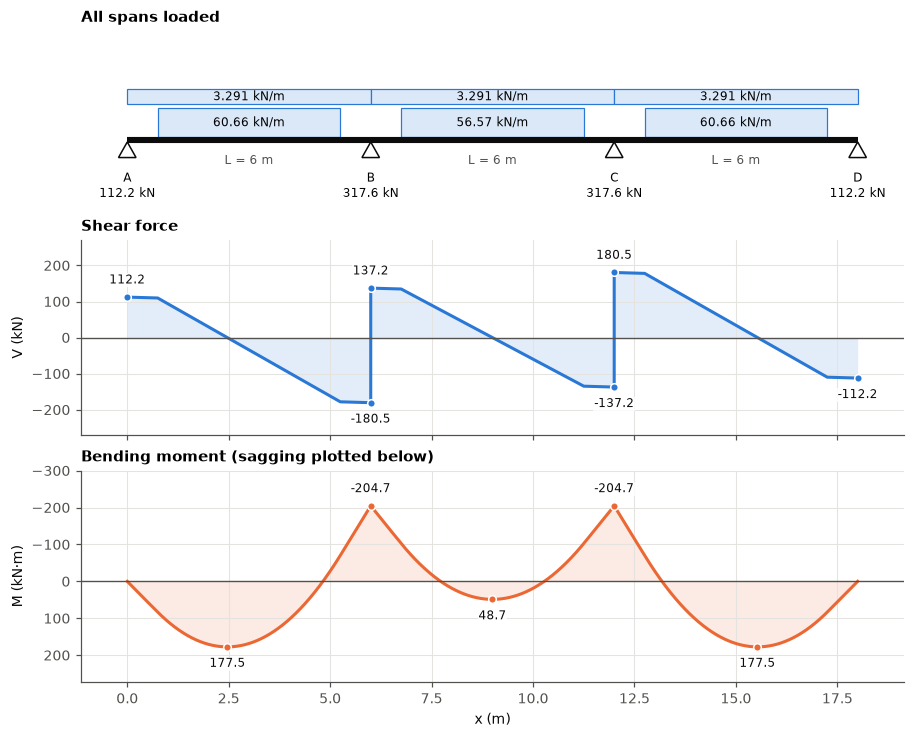

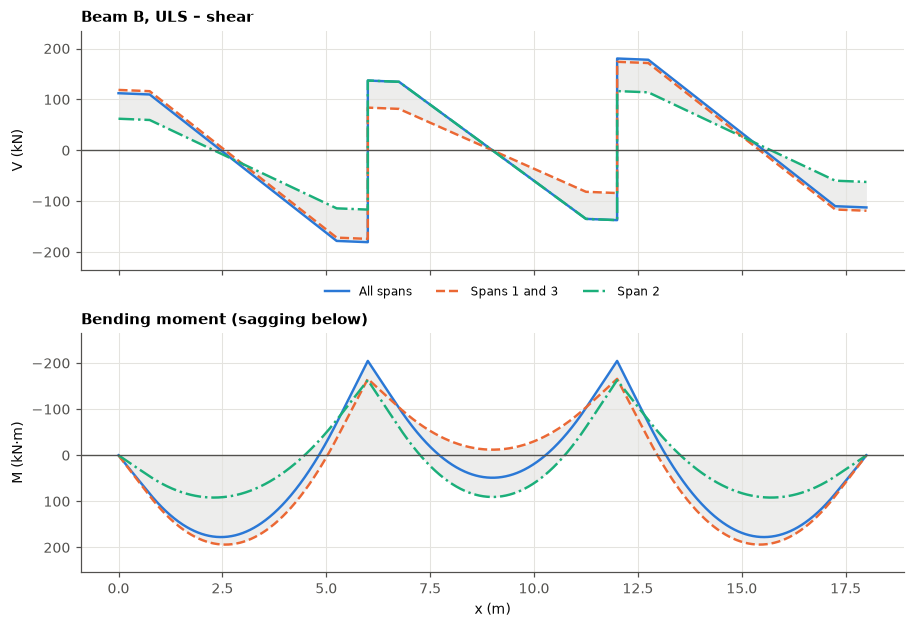

## Beam B

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Beam B, 300 × 500

### Design moments

| Reference | Calculation | Output |
|:--|:--|:--|
|  | **Check:** moment distribution agrees with the three-moment equation in every arrangement | ✅ **PASS** |
|  | Maximum sagging, end span: $M_{AB}$ | $M_{AB} = 193.8$ kN·m |
|  | Maximum sagging, interior span: $M_{BC}$ | $M_{BC} = 90.47$ kN·m |
|  | Maximum hogging at B (support centre-line, not reduced to the face): $M_{B}$ | $M_{B} = -204.7$ kN·m |
| BS 8110-1 3.2.1.2.5 | Moment in each column at B1 (Notebook 1.3): $M_{col}$ | $M_{col} = 49.28$ kN·m |
| EC2 9.2.1.2(1), NA β₁ = 0.25 | Hogging at the end support: code minimum, or the moment passed to the two columns<br>$M_{A} = \max\left\{0.25\,M_{AB};\; 2\,M_{col}\right\}$<br>$\quad = \max\left\{0.25\times 193.8;\; 2\times 49.28\right\}$ | $\mathbf{M_{A} = 98.56}$ kN·m |


In [4]:
b_ = BRIEF
cases = PJ.design_cases("B")
for k, cb in cases.items():
    display(Markdown(f"**Arrangement: {k}**")); mdm_table(cb)
P.continuous(cases["All spans"], "All spans loaded")
x, Vmax, Vmin, Mmax, Mmin = P.envelope(cases, "Beam B, ULS")
tm = max(abs(cb.M_sup - ContinuousBeam(cb.spans).three_moment()).max() for cb in cases.values())
s = Sheet("Beam B", element=f"Beam B, {b_['beam'][0]} × {b_['beam'][1]}")
s.verdict(tm < .01, "moment distribution agrees with the three-moment equation in every arrangement")
L = b_["lx_bay"]; sp1 = x <= L; sp2 = (x >= L) & (x <= 2 * L)
s.let("M_AB", float(Mmax[sp1].max()), "kN·m", "Maximum sagging, end span"); s.let("M_BC", float(Mmax[sp2].max()), "kN·m", "Maximum sagging, interior span"); s.let("M_B", float(Mmin.min()), "kN·m", "Maximum hogging at B (support centre-line, not reduced to the face)")
j = PJ.column_joint("B", 0); s.let("M_col", j["M"], "kN·m", "Moment in each column at B1 (Notebook 1.3)", "BS 8110-1 3.2.1.2.5")
s.calc("M_A", "max(0.25*M_AB, 2*M_col)", "kN·m", "EC2 9.2.1.2(1), NA β₁ = 0.25", "Hogging at the end support: code minimum, or the moment passed to the two columns"); s.show("Design moments")

## 2. Materials, cover, depth, fire

In [5]:
bw, h = b_["beam"]; hf = b_["h_slab"]
D.materials(s, b_["fck"], b_["fyk"], b_["ndp"]); s.let("h", h, "mm")
c = D.cover(s, b_["exposure"], phi, link)
s.calc("d", "h - c_nom - phi_link - phi/2", "mm", "", "Top and bottom steel, one layer"); s.show("Effective depth")
d = s["d"]; D.fire_beam(s, b_["fire"], bw, c + link + phi / 2, c + link + phi / 2, True)

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $h$ | $h = 500$ mm |
|  | Main bar diameter: $\phi$ | $\phi = 20$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
|  | Link diameter: $\phi_{link}$ | $\phi_{link} = 8$ mm |
| EC2 Exp. (4.1), (4.2) | To the link<br>$c_{nom,link} = \max\left\{\phi_{link};\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{8;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{nom,link} = 25}$ mm |
| EC2 Exp. (4.1), (4.2) | To the link, so that the main bar complies<br>$c_{nom,bar} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev} - \phi_{link}$<br>$\quad = \max\left\{20;\; 15;\; 10\right\} + 10 - 8$ | $\mathbf{c_{nom,bar} = 22}$ mm |
|  | $c_{req} = \max\left\{c_{nom,link};\; c_{nom,bar}\right\}$<br>$\quad = \max\left\{25;\; 22\right\}$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Effective depth

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Top and bottom steel, one layer<br>$d = h - c_{nom} - \phi_{link} - \dfrac{\phi}{2}$<br>$\quad = 500 - 25 - 8 - \dfrac{20}{2}$ | $\mathbf{d = 457}$ mm |


### Fire resistance

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Axis distance, soffit: $a_{prov}$ | $a_{prov} = 43$ mm |
|  | Axis distance, side: $a_{sd,prov}$ | $a_{sd,prov} = 43$ mm |
| EN 1992-1-2 Table 5.6 | R 60, tabulated width 200 mm: $a_{req}$ | $a_{req} = 12$ mm |
| EN 1992-1-2 Table 5.6 | Corner bars (no increase; width limit 200 mm): $a_{sd,req}$ | $a_{sd,req} = 12$ mm |
| EN 1992-1-2 Table 5.6 | **Check:** fire – axis distance<br>$a_{prov} = 43 \ge a_{req} = 12$ mm | ✅ **PASS**<br>ratio 0.28 |
| EN 1992-1-2 Table 5.6 | **Check:** fire – side axis distance<br>$a_{sd,prov} = 43 \ge a_{sd,req} = 12$ mm | ✅ **PASS**<br>ratio 0.28 |


## 3. Bending: end span (T-section)

In [6]:
fl = PJ.flange("B", 0)
s.let("b_i", fl["bi"], "mm", "Half the clear distance to the next beam"); s.let("l_1", fl["L"], "mm"); s.let("b_w", bw, "mm")
s.calc("l_0", "0.85*l_1", "mm", "EC2 Fig. 5.2, end span"); s.calc("b_eff_i", "min(0.2*b_i + 0.1*l_0, 0.2*l_0, b_i)", "mm", "EC2 Exp. (5.7a), (5.7b)"); s.calc("b_eff", "2*b_eff_i + b_w", "mm", "EC2 Exp. (5.7)"); s.show("Effective flange")
beff = s["b_eff"]
A_AB, _ = D.flexure_flanged(s, s["M_AB"], beff, bw, hf, d, label="end span"); A_AB_p = D.beam_bars(s, n_AB, phi, bw, c, link, b_["dg"], "bottom, end span"); s.show("End span")
fl2 = PJ.flange("B", 1); s.let("b_eff_2", fl2["beff"], "mm", "Interior span, l₀ = 0.7 l", "EC2 5.3.2.1")
A_BC, _ = D.flexure_flanged(s, s["M_BC"], fl2["beff"], bw, hf, d, label="interior span"); A_BC_p = D.beam_bars(s, n_BC, phi, bw, c, link, b_["dg"], "bottom, interior span"); s.show("Interior span")

### Effective flange

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Half the clear distance to the next beam: $b_{i}$ | $b_{i} = 2350$ mm |
|  | $l_{1}$ | $l_{1} = 6000$ mm |
|  | $b_{w}$ | $b_{w} = 300$ mm |
| EC2 Fig. 5.2, end span | $l_{0} = 0.85\,l_{1}$<br>$\quad = 0.85\times 6000$ | $\mathbf{l_{0} = 5100}$ mm |
| EC2 Exp. (5.7a), (5.7b) | $b_{eff,i} = \min\left\{0.2\,b_{i} + 0.1\,l_{0};\; 0.2\,l_{0};\; b_{i}\right\}$<br>$\quad = \min\left\{0.2\times 2350 + 0.1\times 5100;\; 0.2\times 5100;\; 2350\right\}$ | $\mathbf{b_{eff,i} = 980}$ mm |
| EC2 Exp. (5.7) | $b_{eff} = 2\,b_{eff,i} + b_{w}$<br>$\quad = 2\times 980 + 300$ | $\mathbf{b_{eff} = 2260}$ mm |


### End span

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Exp. (3.21) | $\eta$ | $\eta = 1$  |
|  | Design moment end span: $M_{Ed}$ | $M_{Ed} = 193.8$ kN·m |
|  | Flange thickness: $h_{f}$ | $h_{f} = 175$ mm |
| EC2 3.1.7(3) | Moment capacity with the stress block filling the flange<br>$M_{Rd,f} = \dfrac{\eta\,f_{cd}\,b_{eff}\,h_{f}\,\left(d - \dfrac{h_{f}}{2}\right)}{10^{6}}$<br>$\quad = \dfrac{1\times 17\times 2260\times 175\times \left(457 - \dfrac{175}{2}\right)}{10^{6}}$ | $\mathbf{M_{Rd,f} = 2484.3}$ kN·m |
| EC2 3.1.7(3) | **Check:** stress block within flange end span<br>$M_{Ed} = 193.8 \le M_{Rd,f} = 2484.3$ kN·m | ✅ **PASS**<br>ratio 0.08 |
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | $b$ | $b = 2260$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{193.8\times 10^{6}}{2260\times 457^{2}\times 30}$ | $\mathbf{K = 0.01369}$ |
| EC2 5.5(4) | **Check:** singly reinforced end span<br>$K = 0.01369 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.08 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{457}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.01369\times 30}{1\times 17}}\right);\; 0.95\times 457\right\}$ | $\mathbf{z = 434.1}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(457 - 434.1\right)}{0.8}$ | $\mathbf{x = 57.13}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{193.8\times 10^{6}}{434.8\times 434.1}$ | $\mathbf{A_{s,req} = 1026.6}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 300$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 300\times 457;\; 0.0013\times 300\times 457\right\}$ | $\mathbf{A_{s,min} = 206.5}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{1026.6;\; 206.5\right\}$ | $\mathbf{A_{s,req} = 1026.6}$ mm² |
|  | Number of bars: $n_{bars}$ | $n_{bars} = 4$  |
|  | $A_{s,prov} = \dfrac{n_{bars}\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{4\times \pi\times 20^{2}}{4}$ | $\mathbf{A_{s,prov} = 1256.6}$ mm² |
| EC2 6.1, 9.2.1.1 | **Check:** area provided bottom, end span<br>$A_{s,prov} = 1256.6 \ge A_{s,req} = 1026.6$ mm² | ✅ **PASS**<br>ratio 0.82 |
|  | Maximum aggregate size (project input): $d_{g}$ | $d_{g} = 20$ mm |
|  | Bars in one layer: $n_{layer}$ | $n_{layer} = 4$  |
|  | $s_{clear} = \dfrac{b_{w} - 2\,c_{nom} - 2\,\phi_{link} - n_{layer}\,\phi}{n_{layer} - 1}$<br>$\quad = \dfrac{300 - 2\times 25 - 2\times 8 - 4\times 20}{4 - 1}$ | $\mathbf{s_{clear} = 51.33}$ mm |
| EC2 8.2(2), k₁ = 1, k₂ = 5 mm | $s_{min} = \max\left\{\phi;\; d_{g} + 5;\; 20\right\}$<br>$\quad = \max\left\{20;\; 20 + 5;\; 20\right\}$ | $\mathbf{s_{min} = 25}$ mm |
| EC2 8.2(2) | **Check:** clear bar spacing bottom, end span<br>$s_{clear} = 51.33 \ge s_{min} = 25$ mm | ✅ **PASS**<br>ratio 0.49 |
| EC2 9.2.1.1(3) | $A_{s,max} = 0.04\,b_{w}\,h$<br>$\quad = 0.04\times 300\times 500$ | $\mathbf{A_{s,max} = 6000}$ mm² |
| EC2 9.2.1.1(3) | **Check:** maximum steel bottom, end span<br>$A_{s,prov} = 1256.6 \le A_{s,max} = 6000$ mm² | ✅ **PASS**<br>ratio 0.21 |
|  | **PROVIDE: 4H20 bottom, end span (1257 mm²)** | 🟦 **4H20 bottom, end span (1257 mm²)** |


### Interior span

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.3.2.1 | Interior span, l₀ = 0.7 l: $b_{eff,2}$ | $b_{eff,2} = 1980$ mm |
|  | Design moment interior span: $M_{Ed}$ | $M_{Ed} = 90.47$ kN·m |
| EC2 5.3.2.1 | Effective flange width: $b_{eff}$ | $b_{eff} = 1980$ mm |
| EC2 3.1.7(3) | Moment capacity with the stress block filling the flange<br>$M_{Rd,f} = \dfrac{\eta\,f_{cd}\,b_{eff}\,h_{f}\,\left(d - \dfrac{h_{f}}{2}\right)}{10^{6}}$<br>$\quad = \dfrac{1\times 17\times 1980\times 175\times \left(457 - \dfrac{175}{2}\right)}{10^{6}}$ | $\mathbf{M_{Rd,f} = 2176.5}$ kN·m |
| EC2 3.1.7(3) | **Check:** stress block within flange interior span<br>$M_{Ed} = 90.47 \le M_{Rd,f} = 2176.5$ kN·m | ✅ **PASS**<br>ratio 0.04 |
|  | $b$ | $b = 1980$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{90.47\times 10^{6}}{1980\times 457^{2}\times 30}$ | $\mathbf{K = 0.00729}$ |
| EC2 5.5(4) | **Check:** singly reinforced interior span<br>$K = 0.00729 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.04 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{457}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.00729\times 30}{1\times 17}}\right);\; 0.95\times 457\right\}$ | $\mathbf{z = 434.1}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{90.47\times 10^{6}}{434.8\times 434.1}$ | $\mathbf{A_{s,req} = 479.3}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{479.3;\; 206.5\right\}$ | $\mathbf{A_{s,req} = 479.3}$ mm² |
|  | Number of bars: $n_{bars}$ | $n_{bars} = 2$  |
|  | $A_{s,prov} = \dfrac{n_{bars}\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{2\times \pi\times 20^{2}}{4}$ | $\mathbf{A_{s,prov} = 628.3}$ mm² |
| EC2 6.1, 9.2.1.1 | **Check:** area provided bottom, interior span<br>$A_{s,prov} = 628.3 \ge A_{s,req} = 479.3$ mm² | ✅ **PASS**<br>ratio 0.76 |
|  | Bars in one layer: $n_{layer}$ | $n_{layer} = 2$  |
|  | $s_{clear} = \dfrac{b_{w} - 2\,c_{nom} - 2\,\phi_{link} - n_{layer}\,\phi}{n_{layer} - 1}$<br>$\quad = \dfrac{300 - 2\times 25 - 2\times 8 - 2\times 20}{2 - 1}$ | $\mathbf{s_{clear} = 194}$ mm |
| EC2 8.2(2) | **Check:** clear bar spacing bottom, interior span<br>$s_{clear} = 194 \ge s_{min} = 25$ mm | ✅ **PASS**<br>ratio 0.13 |
| EC2 9.2.1.1(3) | **Check:** maximum steel bottom, interior span<br>$A_{s,prov} = 628.3 \le A_{s,max} = 6000$ mm² | ✅ **PASS**<br>ratio 0.10 |
|  | **PROVIDE: 2H20 bottom, interior span (628 mm²)** | 🟦 **2H20 bottom, interior span (628 mm²)** |


## 4. Bending: supports (rectangular, flange in tension)

In [7]:
A_B, _ = D.flexure(s, s["M_B"], bw, d, label="support B"); A_B_p = D.beam_bars(s, n_B, phi, bw, c, link, b_["dg"], "top, support B"); s.show("Support B")
A_A, _ = D.flexure(s, s["M_A"], bw, d, label="support A"); A_A_p = D.beam_bars(s, n_A, phi, bw, c, link, b_["dg"], "top, support A"); s.show("Support A")
s.note(f"Part of the top steel at B may be spread over the effective flange width (EC2 9.2.1.2(2)). {n_run}H{phi} run through the full length as link hangers and cover the hogging in the interior span when spans 1 and 3 are loaded.", "EC2 9.2.1.2(2)"); s.show()

### Support B

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment support B: $M_{Ed}$ | $M_{Ed} = 204.7$ kN·m |
|  | $b$ | $b = 300$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{204.7\times 10^{6}}{300\times 457^{2}\times 30}$ | $\mathbf{K = 0.109}$ |
| EC2 5.5(4) | **Check:** singly reinforced support B<br>$K = 0.109 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.65 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{457}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.109\times 30}{1\times 17}}\right);\; 0.95\times 457\right\}$ | $\mathbf{z = 407.8}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(457 - 407.8\right)}{0.8}$ | $\mathbf{x = 123.1}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{204.7\times 10^{6}}{434.8\times 407.8}$ | $\mathbf{A_{s,req} = 1154.7}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{1154.7;\; 206.5\right\}$ | $\mathbf{A_{s,req} = 1154.7}$ mm² |
|  | Number of bars: $n_{bars}$ | $n_{bars} = 4$  |
|  | $A_{s,prov} = \dfrac{n_{bars}\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{4\times \pi\times 20^{2}}{4}$ | $\mathbf{A_{s,prov} = 1256.6}$ mm² |
| EC2 6.1, 9.2.1.1 | **Check:** area provided top, support B<br>$A_{s,prov} = 1256.6 \ge A_{s,req} = 1154.7$ mm² | ✅ **PASS**<br>ratio 0.92 |
|  | Bars in one layer: $n_{layer}$ | $n_{layer} = 4$  |
|  | $s_{clear} = \dfrac{b_{w} - 2\,c_{nom} - 2\,\phi_{link} - n_{layer}\,\phi}{n_{layer} - 1}$<br>$\quad = \dfrac{300 - 2\times 25 - 2\times 8 - 4\times 20}{4 - 1}$ | $\mathbf{s_{clear} = 51.33}$ mm |
| EC2 8.2(2) | **Check:** clear bar spacing top, support B<br>$s_{clear} = 51.33 \ge s_{min} = 25$ mm | ✅ **PASS**<br>ratio 0.49 |
| EC2 9.2.1.1(3) | **Check:** maximum steel top, support B<br>$A_{s,prov} = 1256.6 \le A_{s,max} = 6000$ mm² | ✅ **PASS**<br>ratio 0.21 |
|  | **PROVIDE: 4H20 top, support B (1257 mm²)** | 🟦 **4H20 top, support B (1257 mm²)** |


### Support A

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment support A: $M_{Ed}$ | $M_{Ed} = 98.56$ kN·m |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{98.56\times 10^{6}}{300\times 457^{2}\times 30}$ | $\mathbf{K = 0.05243}$ |
| EC2 5.5(4) | **Check:** singly reinforced support A<br>$K = 0.05243 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.31 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{457}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.05243\times 30}{1\times 17}}\right);\; 0.95\times 457\right\}$ | $\mathbf{z = 434.1}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(457 - 434.1\right)}{0.8}$ | $\mathbf{x = 57.13}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{98.56\times 10^{6}}{434.8\times 434.1}$ | $\mathbf{A_{s,req} = 522.1}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{522.1;\; 206.5\right\}$ | $\mathbf{A_{s,req} = 522.1}$ mm² |
|  | Number of bars: $n_{bars}$ | $n_{bars} = 3$  |
|  | $A_{s,prov} = \dfrac{n_{bars}\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{3\times \pi\times 20^{2}}{4}$ | $\mathbf{A_{s,prov} = 942.5}$ mm² |
| EC2 6.1, 9.2.1.1 | **Check:** area provided top, support A<br>$A_{s,prov} = 942.5 \ge A_{s,req} = 522.1$ mm² | ✅ **PASS**<br>ratio 0.55 |
|  | Bars in one layer: $n_{layer}$ | $n_{layer} = 3$  |
|  | $s_{clear} = \dfrac{b_{w} - 2\,c_{nom} - 2\,\phi_{link} - n_{layer}\,\phi}{n_{layer} - 1}$<br>$\quad = \dfrac{300 - 2\times 25 - 2\times 8 - 3\times 20}{3 - 1}$ | $\mathbf{s_{clear} = 87}$ mm |
| EC2 8.2(2) | **Check:** clear bar spacing top, support A<br>$s_{clear} = 87 \ge s_{min} = 25$ mm | ✅ **PASS**<br>ratio 0.29 |
| EC2 9.2.1.1(3) | **Check:** maximum steel top, support A<br>$A_{s,prov} = 942.5 \le A_{s,max} = 6000$ mm² | ✅ **PASS**<br>ratio 0.16 |
|  | **PROVIDE: 3H20 top, support A (942 mm²)** | 🟦 **3H20 top, support A (942 mm²)** |


| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 9.2.1.2(2) | Part of the top steel at B may be spread over the effective flange width (EC2 9.2.1.2(2)). 2H20 run through the full length as link hangers and cover the hogging in the interior span when spans 1 and 3 are loaded. |  |


## 5. Shear

In [8]:
half = b_["col"][0] / 2000; V = np.maximum(Vmax, -Vmin); at = lambda q: float(np.interp(q, x, V))
VBf, VBd = at(L - half), at(L - half - d / 1000); VAf, VAd = at(half), at(half + d / 1000)
cot = D.shear_beam(s, VBf, VBd, bw, d, A_B_p, link, legs, s_near, "near support B"); s.show("Support B, end-span side (largest shear)")
zB = s["z_v"]
D.shear_beam(s, VAf, VAd, bw, d, D.area(phi, n_run), link, legs, s_else, "support A and mid-spans"); s.show("Support A and mid-span zones")
s.let("V_Rd_300", s["V_Rd_s"], "kN", f"Links @ {s_else}"); xx = x[(x <= L) & (V > s["V_Rd_s"]) & (x > L / 2)]
s.let("l_zone", round((L - xx.min()) if len(xx) else 0, 2), "m", f"Distance from B where V exceeds the {s_else} mm link resistance")
zone = math.ceil(max(s["l_zone"], 1.0) * 10) / 10; s.provide(f"H{link} – {legs} legs @ {s_near} for {zone} m each side of interior supports; @ {s_else} elsewhere"); s.show("Link zones")

### Support B, end-span side (largest shear)

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Shear at face of support: $V_{Ed,face}$ | $V_{Ed,face} = 179.9$ kN |
| EC2 6.2.1(8) | Shear at d from face: $V_{Ed,d}$ | $V_{Ed,d} = 178.4$ kN |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 1256.6$ mm² |
| EC2 6.2.2(1), NA | $C_{Rd,c} = \dfrac{0.18}{\gamma_{c}}$<br>$\quad = \dfrac{0.18}{1.5}$ | $\mathbf{C_{Rd,c} = 0.12}$ |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{457}};\; 2\right\}$ | $\mathbf{k = 1.662}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{1256.6}{300\times 457};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00917}$ |
| EC2 Exp. (6.3N) | $v_{min} = 0.035\,k^{1.5}\,\sqrt{f_{ck}}$<br>$\quad = 0.035\times 1.662^{1.5}\times \sqrt{30}$ | $\mathbf{v_{min} = 0.411}$ N/mm²<br><small>(= 0.411 MPa)</small> |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 1.662\times \left(100\times 0.00917\times 30\right)^{1/3};\; 0.411\right\}\times 300\times 457}{1000}$ | $\mathbf{V_{Rd,c} = 82.51}$ kN |
| EC2 6.2.1(3)–(5) | V<sub>Ed</sub> > V<sub>Rd,c</sub>: design shear links. |  |
| EC2 6.2.3(3) Note 3 | Non-prestressed: $\alpha_{cw}$ | $\alpha_{cw} = 1$  |
| EC2 Exp. (6.6N); NA 6.2.3(3) | $\nu_{1} = 0.6\,\left(1 - \dfrac{f_{ck}}{250}\right)$<br>$\quad = 0.6\times \left(1 - \dfrac{30}{250}\right)$ | $\mathbf{\nu_{1} = 0.528}$ |
| NA 3.1.6(1) | α_cc for shear: $\alpha_{cc,v}$ | $\alpha_{cc,v} = 1$  |
| EC2 Exp. (3.15) | $f_{cd,v} = \dfrac{\alpha_{cc,v}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{1\times 30}{1.5}$ | $\mathbf{f_{cd,v} = 20}$ N/mm²<br><small>(= 20 MPa)</small> |
| EC2 6.2.3(1) | $z_{v} = 0.9\,d$<br>$\quad = 0.9\times 457$ | $\mathbf{z_{v} = 411.3}$ mm |
| EC2 Exp. (6.9), cot θ = 1 | $V_{Rd,max,45} = \dfrac{\dfrac{\alpha_{cw}\,b_{w}\,z_{v}\,\nu_{1}\,f_{cd,v}}{1 + 1}}{1000}$<br>$\quad = \dfrac{\dfrac{1\times 300\times 411.3\times 0.528\times 20}{1 + 1}}{1000}$ | $\mathbf{V_{Rd,max,45} = 651.5}$ kN |
| EC2 6.2.1(8), 6.2.3(3) | **Check:** strut crushing at face near support B<br>$V_{Ed,face} = 179.9 \le V_{Rd,max,45} = 651.5$ kN | ✅ **PASS**<br>ratio 0.28 |
| EC2 Exp. (6.9) rearranged (Notebook 2.3) | Strut angle that just satisfies V_Rd,max<br>$\theta_{min} = \dfrac{0.5\,\sin^{-1}\!\left(\min\left\{\dfrac{V_{Ed,face}}{V_{Rd,max,45}};\; 1\right\}\right)\times 180}{\pi}$<br>$\quad = \dfrac{0.5\times \sin^{-1}\!\left(\min\left\{\dfrac{179.9}{651.5};\; 1\right\}\right)\times 180}{\pi}$ | $\mathbf{\theta_{min} = 8.015}$ ° |
| EC2 Exp. (6.7N), NA | Limited to 1 ≤ cot θ ≤ 2.5: $\cot\theta$ | $\cot\theta = 2.5$  |
| EC2 Exp. (6.8) | $A_{sw,s,req} = \dfrac{V_{Ed,d}\times 1000}{z_{v}\,f_{yd}\,\cot\theta}$<br>$\quad = \dfrac{178.4\times 1000}{411.3\times 434.8\times 2.5}$ | $\mathbf{A_{sw,s,req} = 0.399}$ mm²/mm |
| EC2 Exp. (9.4), (9.5N) | $A_{sw,s,min} = \dfrac{0.08\,\sqrt{f_{ck}}}{f_{yk}}\,b_{w}$<br>$\quad = \dfrac{0.08\times \sqrt{30}}{500}\times 300$ | $\mathbf{A_{sw,s,min} = 0.263}$ mm²/mm |
|  | Number of legs: $n_{legs}$ | $n_{legs} = 2$  |
|  | Link spacing: $s_{link}$ | $s_{link} = 200$ mm |
|  | $A_{sw,s} = \dfrac{\dfrac{n_{legs}\,\pi\,\phi_{link}^{2}}{4}}{s_{link}}$<br>$\quad = \dfrac{\dfrac{2\times \pi\times 8^{2}}{4}}{200}$ | $\mathbf{A_{sw,s} = 0.503}$ mm²/mm |
| EC2 9.2.2(5) | **Check:** minimum links near support B<br>$A_{sw,s} = 0.503 \ge A_{sw,s,min} = 0.263$ mm²/mm | ✅ **PASS**<br>ratio 0.52 |
| EC2 6.2.3(3) | **Check:** design links near support B<br>$A_{sw,s} = 0.503 \ge A_{sw,s,req} = 0.399$ mm²/mm | ✅ **PASS**<br>ratio 0.79 |
| EC2 Exp. (9.6N) | $s_{l,max} = 0.75\,d$<br>$\quad = 0.75\times 457$ | $\mathbf{s_{l,max} = 342.8}$ mm |
| EC2 9.2.2(6) | **Check:** longitudinal link spacing near support B<br>$s_{link} = 200 \le s_{l,max} = 342.8$ mm | ✅ **PASS**<br>ratio 0.58 |
| EC2 Exp. (9.8N) | Maximum transverse leg spacing: $s_{t,max}$ | $s_{t,max} = 342.8$ mm |
| EC2 Exp. (6.8) | Resistance of the links provided<br>$V_{Rd,s} = \dfrac{A_{sw,s}\,z_{v}\,f_{yd}\,\cot\theta}{1000}$<br>$\quad = \dfrac{0.503\times 411.3\times 434.8\times 2.5}{1000}$ | $\mathbf{V_{Rd,s} = 224.7}$ kN |
|  | **PROVIDE: H8 – 2 legs @ 200 mm near support B** | 🟦 **H8 – 2 legs @ 200 mm near support B** |


### Support A and mid-span zones

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Shear at face of support: $V_{Ed,face}$ | $V_{Ed,face} = 118.1$ kN |
| EC2 6.2.1(8) | Shear at d from face: $V_{Ed,d}$ | $V_{Ed,d} = 116.6$ kN |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 628.3$ mm² |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{628.3}{300\times 457};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00458}$ |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 1.662\times \left(100\times 0.00458\times 30\right)^{1/3};\; 0.411\right\}\times 300\times 457}{1000}$ | $\mathbf{V_{Rd,c} = 65.49}$ kN |
| EC2 6.2.1(3)–(5) | V<sub>Ed</sub> > V<sub>Rd,c</sub>: design shear links. |  |
| EC2 6.2.1(8), 6.2.3(3) | **Check:** strut crushing at face support A and mid-spans<br>$V_{Ed,face} = 118.1 \le V_{Rd,max,45} = 651.5$ kN | ✅ **PASS**<br>ratio 0.18 |
| EC2 Exp. (6.9) rearranged (Notebook 2.3) | Strut angle that just satisfies V_Rd,max<br>$\theta_{min} = \dfrac{0.5\,\sin^{-1}\!\left(\min\left\{\dfrac{V_{Ed,face}}{V_{Rd,max,45}};\; 1\right\}\right)\times 180}{\pi}$<br>$\quad = \dfrac{0.5\times \sin^{-1}\!\left(\min\left\{\dfrac{118.1}{651.5};\; 1\right\}\right)\times 180}{\pi}$ | $\mathbf{\theta_{min} = 5.224}$ ° |
| EC2 Exp. (6.8) | $A_{sw,s,req} = \dfrac{V_{Ed,d}\times 1000}{z_{v}\,f_{yd}\,\cot\theta}$<br>$\quad = \dfrac{116.6\times 1000}{411.3\times 434.8\times 2.5}$ | $\mathbf{A_{sw,s,req} = 0.261}$ mm²/mm |
|  | Link spacing: $s_{link}$ | $s_{link} = 300$ mm |
|  | $A_{sw,s} = \dfrac{\dfrac{n_{legs}\,\pi\,\phi_{link}^{2}}{4}}{s_{link}}$<br>$\quad = \dfrac{\dfrac{2\times \pi\times 8^{2}}{4}}{300}$ | $\mathbf{A_{sw,s} = 0.335}$ mm²/mm |
| EC2 9.2.2(5) | **Check:** minimum links support A and mid-spans<br>$A_{sw,s} = 0.335 \ge A_{sw,s,min} = 0.263$ mm²/mm | ✅ **PASS**<br>ratio 0.78 |
| EC2 6.2.3(3) | **Check:** design links support A and mid-spans<br>$A_{sw,s} = 0.335 \ge A_{sw,s,req} = 0.261$ mm²/mm | ✅ **PASS**<br>ratio 0.78 |
| EC2 9.2.2(6) | **Check:** longitudinal link spacing support A and mid-spans<br>$s_{link} = 300 \le s_{l,max} = 342.8$ mm | ✅ **PASS**<br>ratio 0.88 |
| EC2 Exp. (6.8) | Resistance of the links provided<br>$V_{Rd,s} = \dfrac{A_{sw,s}\,z_{v}\,f_{yd}\,\cot\theta}{1000}$<br>$\quad = \dfrac{0.335\times 411.3\times 434.8\times 2.5}{1000}$ | $\mathbf{V_{Rd,s} = 149.8}$ kN |
|  | **PROVIDE: H8 – 2 legs @ 300 mm support A and mid-spans** | 🟦 **H8 – 2 legs @ 300 mm support A and mid-spans** |


### Link zones

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Links @ 300: $V_{Rd,300}$ | $V_{Rd,300} = 149.8$ kN |
|  | Distance from B where V exceeds the 300 mm link resistance: $l_{zone}$ | $l_{zone} = 1.19$ m |
|  | **PROVIDE: H8 – 2 legs @ 200 for 1.2 m each side of interior supports; @ 300 elsewhere** | 🟦 **H8 – 2 legs @ 200 for 1.2 m each side of interior supports; @ 300 elsewhere** |


## 6. Shear between flange and web

In [9]:
gg, qq = PJ.area_loads(); lxs = b_["ly_bay"]; mneg = SL.two_way("two adjacent edges discontinuous", b_["lx_bay"] / lxs)["sx_neg"] * (1.35 * gg + 1.5 * qq) * lxs**2
A_bend = mneg * 1e6 / (s["f_yd"] * .95 * (hf - 30))          # slab top steel required over Beam B (Notebook 3.3)
x0 = x[sp1][Mmax[sp1].argmax()]; mh = float(np.interp(x0 / 2, x, Mmax))
D.flange_shear(s, max(mh, s["M_AB"] - mh), beff, fl["beffi"], hf, x0 / 2 * 1000, 0.95 * d, D.area(slab_top[0]) * 1000 / slab_top[1] + D.area(slab_bot[0]) * 1000 / slab_bot[1], A_bend); s.show("Web–flange shear, end span")
s.note(f"Slab steel over Beam B from Notebook 3.3: H{slab_top[0]} @ {slab_top[1]} top and H{slab_bot[0]} @ {slab_bot[1]} bottom."); s.show()

### Web–flange shear, end span

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Change of moment over Δx: $\Delta M$ | $\Delta M = 141.2$ kN·m |
| EC2 6.2.4(3) | Half the distance between M = 0 and M_max: $\Delta x$ | $\Delta x = 1285$ mm |
|  | $b_{eff}$ | $b_{eff} = 2260$ mm |
|  | One flange outstand: $b_{eff,1}$ | $b_{eff,1} = 980$ mm |
| EC2 6.2.4(3) | Force change in one outstand<br>$\Delta F_d = \dfrac{\dfrac{\Delta M\times 1000}{z}\,b_{eff,1}}{b_{eff}}$<br>$\quad = \dfrac{\dfrac{141.2\times 1000}{434.1}\times 980}{2260}$ | $\mathbf{\Delta F_d = 141}$ kN |
| EC2 Exp. (6.20) | $v_{Ed,f} = \dfrac{\Delta F_d\times 1000}{h_{f}\,\Delta x}$<br>$\quad = \dfrac{141\times 1000}{175\times 1285}$ | $\mathbf{v_{Ed,f} = 0.627}$ N/mm²<br><small>(= 0.627 MPa)</small> |
| EC2 Exp. (3.16) | $f_{ctd} = \dfrac{0.7\,f_{ctm}}{\gamma_{c}}$<br>$\quad = \dfrac{0.7\times 2.896}{1.5}$ | $\mathbf{f_{ctd} = 1.352}$ N/mm²<br><small>(= 1.352 MPa)</small> |
| EC2 6.2.4(6), NA | $v_{lim} = 0.4\,f_{ctd}$<br>$\quad = 0.4\times 1.352$ | $\mathbf{v_{lim} = 0.541}$ N/mm²<br><small>(= 0.541 MPa)</small> |
| EC2 6.2.4(4), NA | Compression flange: $\cot\theta$ | $\cot\theta = 2$  |
| EC2 Exp. (6.6N) | $\nu = 0.6\,\left(1 - \dfrac{f_{ck}}{250}\right)$<br>$\quad = 0.6\times \left(1 - \dfrac{30}{250}\right)$ | $\mathbf{\nu = 0.528}$ |
| EC2 Exp. (6.22) | ν f_cd sin θ cos θ (with α_cc = 0.85, conservative)<br>$v_{max} = \dfrac{\nu\,f_{cd}\,\cot\theta}{1 + \cot\theta^{2}}$<br>$\quad = \dfrac{0.528\times 17\times 2}{1 + 2^{2}}$ | $\mathbf{v_{max} = 3.59}$ N/mm²<br><small>(= 3.59 MPa)</small> |
| EC2 6.2.4(4) | **Check:** flange struts<br>$v_{Ed,f} = 0.627 \le v_{max} = 3.59$ N/mm²<br><small>(= 0.627 ≤ 3.59 MPa)</small> | ✅ **PASS**<br>ratio 0.17 |
| EC2 Exp. (6.21) | $A_{sf} = \dfrac{v_{Ed,f}\,h_{f}}{\cot\theta\,f_{yd}}\times 1000$<br>$\quad = \dfrac{0.627\times 175}{2\times 434.8}\times 1000$ | $\mathbf{A_{sf} = 126.2}$ mm²/m |
|  | Slab bending steel at the beam: $A_{bend}$ | $A_{bend} = 358.5$ mm²/m |
| EC2 6.2.4(5) | $A_{comb} = \max\left\{A_{sf};\; 0.5\,A_{sf} + A_{bend}\right\}$<br>$\quad = \max\left\{126.2;\; 0.5\times 126.2 + 358.5\right\}$ | $\mathbf{A_{comb} = 421.6}$ mm²/m |
|  | Transverse slab steel crossing the junction (top + bottom): $A_{trans}$ | $A_{trans} = 706.9$ mm²/m |
| EC2 6.2.4(4), (5) | **Check:** flange transverse steel<br>$A_{trans} = 706.9 \ge A_{comb} = 421.6$ mm²/m | ✅ **PASS**<br>ratio 0.60 |


| Reference | Calculation | Output |
|:--|:--|:--|
|  | Slab steel over Beam B from Notebook 3.3: H10 @ 200 top and H10 @ 250 bottom. |  |


## 7. Deflection and cracking

In [10]:
D.deflection(s, L * 1000, d, beff, A_AB, A_AB_p, "end span", bf_bw=beff / bw, partitions=True); s.show("Deflection, end span")
cc, w = PJ.line_loads(); gk = w["B"][0][0] * .75 + PJ.downstand(); qk = w["B"][0][1] * .75
sb, sB = [(bw - 2 * c - 2 * link - phi) / (k - 1) for k in (n_AB, n_B)]
D.crack(s, gk, qk, PSI[b_["category"]][2], A_AB, A_AB_p, sb, h, label="end span"); D.crack_min(s, bw, h, A_AB_p, "end span"); s.show("Cracking, end span")
D.crack(s, gk, qk, PSI[b_["category"]][2], A_B, A_B_p, sB, h, label="support B"); s.show("Cracking, support B")

### Deflection, end span

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 7.4N / NA.5 | Structural system: end span: $K_{sys}$ | $K_{sys} = 1.3$  |
|  | Effective span: $l_{eff}$ | $l_{eff} = 6000$ mm |
| EC2 7.4.2(2) | 10⁻³ √fck: $\rho_{0}$ | $\rho_{0} = 0.00548$  |
|  | Steel required for ULS at mid-span: $A_{s,ult}$ | $A_{s,ult} = 1026.6$ mm² |
|  | $b$ | $b = 2260$ mm |
| EC2 7.4.2(2) | $\rho = \dfrac{A_{s,ult}}{b\,d}$<br>$\quad = \dfrac{1026.6}{2260\times 457}$ | $\mathbf{\rho = 9.940\times10^{-4}}$ |
| EC2 Exp. (7.16a) | Basic l/d<br>$N_{basic} = K_{sys}\,\left(11 + \dfrac{1.5\,\sqrt{f_{ck}}\,\rho_{0}}{\rho} + 3.2\,\sqrt{f_{ck}}\,\left(\dfrac{\rho_{0}}{\rho} - 1\right)^{1.5}\right)$<br>$\quad = 1.3\times \left(11 + \dfrac{1.5\times \sqrt{30}\times 0.00548}{9.940\times10^{-4}} + 3.2\times \sqrt{30}\times \left(\dfrac{0.00548}{9.940\times10^{-4}} - 1\right)^{1.5}\right)$ | $\mathbf{N_{basic} = 291.4}$ |
| EC2 7.4.2(2) | Flanged section, b_f/b_w = 7.53: $F_{1}$ | $F_{1} = 0.8$  |
| EC2 7.4.2(2) | Span > 7 m with brittle partitions: $F_{2}$ | $F_{2} = 1$  |
|  | $A_{s,prov}$ | $A_{s,prov} = 1256.6$ mm² |
| NA Table NA.5 Note 5 | Cap on the steel-stress factor: $F_{cap}$ | $F_{cap} = 1.5$  |
| EC2 Exp. (7.17), NA Note 5 | $F_{3} = \min\left\{\dfrac{500}{\dfrac{f_{yk}\,A_{s,ult}}{A_{s,prov}}};\; F_{cap}\right\}$<br>$\quad = \min\left\{\dfrac{500}{\dfrac{500\times 1026.6}{1256.6}};\; 1.5\right\}$ | $\mathbf{F_{3} = 1.224}$ |
| NA Table NA.5 Note 6 | Absolute limit 40K: $N_{abs}$ | $N_{abs} = 40$  |
| EC2 7.4.2(2), NA | $N_{allow} = \min\left\{N_{basic}\,F_{1}\,F_{2}\,F_{3};\; N_{abs}\,K_{sys}\right\}$<br>$\quad = \min\left\{291.4\times 0.8\times 1\times 1.224;\; 40\times 1.3\right\}$ | $\mathbf{N_{allow} = 52}$ |
|  | $N_{actual} = \dfrac{l_{eff}}{d}$<br>$\quad = \dfrac{6000}{457}$ | $\mathbf{N_{actual} = 13.13}$ |
| EC2 7.4.2 | **Check:** deflection (span/depth)<br>$N_{actual} = 13.13 \le N_{allow} = 52$  | ✅ **PASS**<br>ratio 0.25 |


### Cracking, end span

| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1990 Table A1.1 | Quasi-permanent factor: $\psi_{2}$ | $\psi_{2} = 0.3$  |
|  | Permanent load on the member: $G_{k}$ | $G_{k} = 22.05$  |
|  | Variable load on the member: $Q_{k}$ | $Q_{k} = 12.68$  |
| EN 1990 (6.16b); method as JRC EUR 26566 (2014) 3.3.1.3 | Steel stress, quasi-permanent load<br>$\sigma_{s} = \dfrac{\dfrac{\dfrac{f_{yd}\,\left(G_{k} + \psi_{2}\,Q_{k}\right)}{1.35\,G_{k} + 1.5\,Q_{k}}\,A_{s,ult}}{A_{s,prov}}}{\delta}$<br>$\quad = \dfrac{\dfrac{\dfrac{434.8\times \left(22.05 + 0.3\times 12.68\right)}{1.35\times 22.05 + 1.5\times 12.68}\times 1026.6}{1256.6}}{1}$ | $\mathbf{\sigma_{s} = 188.2}$ N/mm²<br><small>(= 188.2 MPa)</small> |
| EC2 Table 7.3N, NA.4 | Maximum bar spacing, w_k = 0.3 mm (next higher tabulated stress, no interpolation): $s_{crack}$ | $s_{crack} = 250$ mm |
|  | Bar spacing provided (centres): $s_{bars}$ | $s_{bars} = 71.33$ mm |
| EC2 7.3.3(2) | **Check:** crack control end span<br>$s_{bars} = 71.33 \le s_{crack} = 250$ mm | ✅ **PASS**<br>ratio 0.29 |
| EC2 Exp. (7.2) | Bending, σ_c = 0: $k_{c}$ | $k_{c} = 0.4$  |
| EC2 7.3.2(2) | Coefficient k, interpolated on depth: $k_{h}$ | $k_{h} = 0.86$  |
|  | $b$ | $b = 300$ mm |
| EC2 7.3.2(2) | Tension zone before cracking<br>$A_{ct} = \dfrac{b\,h}{2}$<br>$\quad = \dfrac{300\times 500}{2}$ | $\mathbf{A_{ct} = 75000}$ mm² |
| EC2 Exp. (7.1), σ_s = f_yk | $A_{s,crack} = \dfrac{k_{c}\,k_{h}\,f_{ctm}\,A_{ct}}{f_{yk}}$<br>$\quad = \dfrac{0.4\times 0.86\times 2.896\times 75000}{500}$ | $\mathbf{A_{s,crack} = 149.5}$ mm² |
| EC2 7.3.2 | **Check:** minimum steel for cracking end span<br>$A_{s,prov} = 1256.6 \ge A_{s,crack} = 149.5$ mm² | ✅ **PASS**<br>ratio 0.12 |


### Cracking, support B

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $A_{s,ult}$ | $A_{s,ult} = 1154.7$ mm² |
| EN 1990 (6.16b); method as JRC EUR 26566 (2014) 3.3.1.3 | Steel stress, quasi-permanent load<br>$\sigma_{s} = \dfrac{\dfrac{\dfrac{f_{yd}\,\left(G_{k} + \psi_{2}\,Q_{k}\right)}{1.35\,G_{k} + 1.5\,Q_{k}}\,A_{s,ult}}{A_{s,prov}}}{\delta}$<br>$\quad = \dfrac{\dfrac{\dfrac{434.8\times \left(22.05 + 0.3\times 12.68\right)}{1.35\times 22.05 + 1.5\times 12.68}\times 1154.7}{1256.6}}{1}$ | $\mathbf{\sigma_{s} = 211.7}$ N/mm²<br><small>(= 211.7 MPa)</small> |
| EC2 Table 7.3N, NA.4 | Maximum bar spacing, w_k = 0.3 mm (next higher tabulated stress, no interpolation): $s_{crack}$ | $s_{crack} = 200$ mm |
| EC2 7.3.3(2) | **Check:** crack control support B<br>$s_{bars} = 71.33 \le s_{crack} = 200$ mm | ✅ **PASS**<br>ratio 0.36 |


## 8. Anchorage, laps and curtailment

### Anchorage, bottom bars at full stress

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $\cot\theta$ | $\cot\theta = 2.5$  |
| EC2 Exp. (9.2) | Shift of the moment envelope<br>$a_{l} = \dfrac{z_{v}\,\cot\theta}{2}$<br>$\quad = \dfrac{411.3\times 2.5}{2}$ | $\mathbf{a_{l} = 514.1}$ mm |
| EC2 Table 3.1 | $f_{ctk,005} = 0.7\,f_{ctm}$<br>$\quad = 0.7\times 2.896$ | $\mathbf{f_{ctk,005} = 2.028}$ N/mm²<br><small>(= 2.028 MPa)</small> |
| EC2 3.1.6(2), NA | $\alpha_{ct}$ | $\alpha_{ct} = 1$  |
| EC2 Exp. (3.16) | $f_{ctd} = \dfrac{\alpha_{ct}\,f_{ctk,005}}{\gamma_{c}}$<br>$\quad = \dfrac{1\times 2.028}{1.5}$ | $\mathbf{f_{ctd} = 1.352}$ N/mm²<br><small>(= 1.352 MPa)</small> |
| EC2 8.4.2, Fig. 8.2 | Good bond: $\eta_{1}$ | $\eta_{1} = 1$  |
| EC2 8.4.2 | φ ≤ 32 mm: $\eta_{2}$ | $\eta_{2} = 1$  |
| EC2 Exp. (8.2) | $f_{bd} = 2.25\,\eta_{1}\,\eta_{2}\,f_{ctd}$<br>$\quad = 2.25\times 1\times 1\times 1.352$ | $\mathbf{f_{bd} = 3.041}$ N/mm²<br><small>(= 3.041 MPa)</small> |
| EC2 8.4.3(2) | Design bar stress: $\sigma_{sd}$ | $\sigma_{sd} = 434.8$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Exp. (8.3) | $l_{b,rqd} = \dfrac{\dfrac{\phi}{4}\,\sigma_{sd}}{f_{bd}}$<br>$\quad = \dfrac{\dfrac{20}{4}\times 434.8}{3.041}$ | $\mathbf{l_{b,rqd} = 714.8}$ mm |
| EC2 Table 8.2 | Cover coefficient (others = 1.0, conservative): $\alpha_{2}$ | $\alpha_{2} = 1$  |
| EC2 Exp. (8.6)/(8.7) | Tension: $f_{lmin}$ | $f_{lmin} = 0.3$  |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.3\times 714.8;\; 10\times 20;\; 100\right\}$ | $\mathbf{l_{b,min} = 214.4}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 714.8;\; 214.4\right\}$ | $\mathbf{l_{bd} = 714.8}$ mm |


### Anchorage and lap, top bars at full stress (50% lapped)

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 8.4.2, Fig. 8.2 | Poor bond (top bars, h > 250 mm): $\eta_{1}$ | $\eta_{1} = 0.7$  |
| EC2 Exp. (8.2) | $f_{bd} = 2.25\,\eta_{1}\,\eta_{2}\,f_{ctd}$<br>$\quad = 2.25\times 0.7\times 1\times 1.352$ | $\mathbf{f_{bd} = 2.129}$ N/mm²<br><small>(= 2.129 MPa)</small> |
| EC2 Exp. (8.3) | $l_{b,rqd} = \dfrac{\dfrac{\phi}{4}\,\sigma_{sd}}{f_{bd}}$<br>$\quad = \dfrac{\dfrac{20}{4}\times 434.8}{2.129}$ | $\mathbf{l_{b,rqd} = 1021.1}$ mm |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.3\times 1021.1;\; 10\times 20;\; 100\right\}$ | $\mathbf{l_{b,min} = 306.3}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 1021.1;\; 306.3\right\}$ | $\mathbf{l_{bd} = 1021.1}$ mm |
| EC2 8.7.3 | 50% lapped: $\alpha_{6}$ | $\alpha_{6} = 1.414$  |
| EC2 Exp. (8.10), (8.11) | $l_{0,lap} = \max\left\{\alpha_{2}\,\alpha_{6}\,l_{b,rqd};\; 0.3\,\alpha_{6}\,l_{b,rqd};\; 15\,\phi;\; 200\right\}$<br>$\quad = \max\left\{1\times 1.414\times 1021.1;\; 0.3\times 1.414\times 1021.1;\; 15\times 20;\; 200\right\}$ | $\mathbf{l_{0,lap} = 1444.1}$ mm |


### Bottom bars at end support A

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Shear at support A: $V_{Ed}$ | $V_{Ed} = 118.1$ kN |
| EC2 Exp. (9.3) | Force to anchor at A<br>$F_{E} = \dfrac{V_{Ed}\,a_{l}}{z_{v}}$<br>$\quad = \dfrac{118.1\times 514.1}{411.3}$ | $\mathbf{F_{E} = 147.7}$ kN |
|  | 2H20 carried into the support: $A_{s,prov}$ | $A_{s,prov} = 628.3$ mm² |
|  | $\sigma_{E} = \dfrac{F_{E}\times 1000}{A_{s,prov}}$<br>$\quad = \dfrac{147.7\times 1000}{628.3}$ | $\mathbf{\sigma_{E} = 235}$ N/mm²<br><small>(= 235 MPa)</small> |
| EC2 8.4.2, Fig. 8.2 | Good bond: $\eta_{1}$ | $\eta_{1} = 1$  |
| EC2 Exp. (8.2) | $f_{bd} = 2.25\,\eta_{1}\,\eta_{2}\,f_{ctd}$<br>$\quad = 2.25\times 1\times 1\times 1.352$ | $\mathbf{f_{bd} = 3.041}$ N/mm²<br><small>(= 3.041 MPa)</small> |
| EC2 8.4.3(2) | Design bar stress: $\sigma_{sd}$ | $\sigma_{sd} = 235$ N/mm²<br><small>(= 235 MPa)</small> |
| EC2 Exp. (8.3) | $l_{b,rqd} = \dfrac{\dfrac{\phi}{4}\,\sigma_{sd}}{f_{bd}}$<br>$\quad = \dfrac{\dfrac{20}{4}\times 235}{3.041}$ | $\mathbf{l_{b,rqd} = 386.4}$ mm |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.3\times 386.4;\; 10\times 20;\; 100\right\}$ | $\mathbf{l_{b,min} = 200}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 386.4;\; 200\right\}$ | $\mathbf{l_{bd} = 386.4}$ mm |
|  | Support width: $W$ | $W = 350$ mm |
|  | Straight length available<br>$l_{straight} = W - c_{nom}$<br>$\quad = 350 - 25$ | $\mathbf{l_{straight} = 325}$ mm |
| EC2 8.4.1(2), Fig. 8.1 | A straight bar does not have enough length, so a 90° bend is provided. |  |
| NA Table NA.6a | Minimum mandrel diameter / φ: $k_{m}$ | $k_{m} = 7$  |
|  | Radius of the bar centre-line<br>$r_{c} = \dfrac{k_{m}\,\phi + \phi}{2}$<br>$\quad = \dfrac{7\times 20 + 20}{2}$ | $\mathbf{r_{c} = 80}$ mm |
|  | Vertical leg, from the centre of the horizontal bar: $l_{leg}$ | $l_{leg} = 200$ mm |
| EC2 8.4.3(3) | Length along the centre-line<br>$l_{bent} = W - c_{nom} - \dfrac{\phi}{2} + l_{leg} - \left(2 - \dfrac{\pi}{2}\right)\,r_{c}$<br>$\quad = 350 - 25 - \dfrac{20}{2} + 200 - \left(2 - \dfrac{\pi}{2}\right)\times 80$ | $\mathbf{l_{bent} = 480.7}$ mm |
| EC2 9.2.1.4(3), 8.4.3(3) | **Check:** bent-bar anchorage bottom bars at A<br>$l_{bent} = 480.7 \ge l_{bd} = 386.4$ mm | ✅ **PASS**<br>ratio 0.80 |
| EC2 8.3(3) | Length needed past the end of the bend<br>$l_{past} = \max\left\{l_{bd} - \left(W - c_{nom} - \dfrac{\phi}{2} - r_{c}\right) - \dfrac{\pi\,r_{c}}{2};\; 0\right\}$<br>$\quad = \max\left\{386.4 - \left(350 - 25 - \dfrac{20}{2} - 80\right) - \dfrac{\pi\times 80}{2};\; 0\right\}$ | $\mathbf{l_{past} = 25.75}$ mm |
| EC2 8.3(3) | $l_{5} = 5\,\phi$<br>$\quad = 5\times 20$ | $\mathbf{l_{5} = 100}$ mm |
| EC2 8.3(3) | **Check:** no mandrel check needed bottom bars at A<br>$l_{past} = 25.75 \le l_{5} = 100$ mm | ✅ **PASS**<br>ratio 0.26 |
| EC2 8.3(3) | Provide a cross bar of diameter ≥ φ inside the bend. |  |
|  | **PROVIDE: 90° bend, 200 mm leg bottom bars at A** | 🟦 **90° bend, 200 mm leg bottom bars at A** |
|  | β₂ = 0.25 of span steel: $A_{s,25}$ | $A_{s,25} = 314.2$ mm² |
| EC2 9.2.1.4(1) | **Check:** bottom steel continued to the end support<br>$A_{s,prov} = 628.3 \ge A_{s,25} = 314.2$ mm² | ✅ **PASS**<br>ratio 0.50 |


### Curtailment

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 6.1 | Span capacity with 2H20 (z = 0.95d, flanged)<br>$M_{Rd,2} = \dfrac{A_{s,prov}\,f_{yd}\times 0.95\,d}{10^{6}}$<br>$\quad = \dfrac{628.3\times 434.8\times 0.95\times 457}{10^{6}}$ | $\mathbf{M_{Rd,2} = 118.6}$ kN·m |
| EC2 3.1.7(3) | $z_{2} = d - \dfrac{A_{s,prov}\,f_{yd}}{2\,\eta\,f_{cd}\,b}$<br>$\quad = 457 - \dfrac{628.3\times 434.8}{2\times 1\times 17\times 300}$ | $\mathbf{z_{2} = 430.2}$ mm |
| EC2 6.1 | Hogging capacity with 2H20<br>$M_{Rd,2h} = \dfrac{A_{s,prov}\,f_{yd}\,z_{2}}{10^{6}}$<br>$\quad = \dfrac{628.3\times 434.8\times 430.2}{10^{6}}$ | $\mathbf{M_{Rd,2h} = 117.5}$ kN·m |
| EC2 9.2.1.3 | Start of the 2 extra bottom bars, from grid 1 (shifted envelope + l_bd): $x_{b1}$ | $x_{b1} = 0$ m |
|  | End of the 2 extra bottom bars: $x_{b2}$ | $x_{b2} = 5.32$ m |
| EC2 9.2.1.3 | Start of the 2 extra top bars at B: $x_{t1}$ | $x_{t1} = 3.99$ m |
|  | End of the 2 extra top bars at B: $x_{t2}$ | $x_{t2} = 8.17$ m |


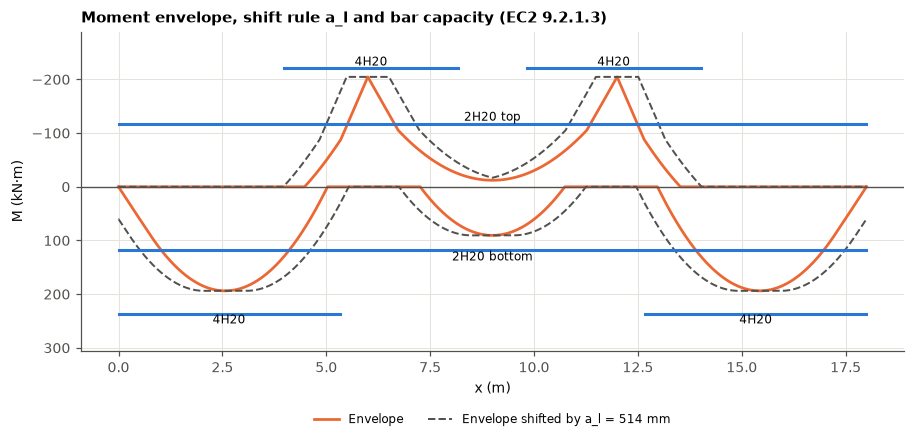

In [11]:
s.let("cot_theta", cot); s.let("z_v", zB, "mm"); s.calc("a_l", "z_v*cot_theta/2", "mm", "EC2 Exp. (9.2)", "Shift of the moment envelope")
lb_bot = D.anchorage(s, phi, label="bottom (good bond)"); s.show("Anchorage, bottom bars at full stress")
lb_top, lap_top = D.anchorage(s, phi, good=False, lap_pct=lap_pct, label="top (poor bond, h > 250 mm)"); s.show("Anchorage and lap, top bars at full stress (" + f"{lap_pct}% lapped)")
s.let("V_Ed", VAf, "kN", "Shear at support A"); s.calc("F_E", "V_Ed*a_l/z_v", "kN", "EC2 Exp. (9.3)", "Force to anchor at A"); s.let("A_s_prov", D.area(phi, n_run), "mm²", f"{n_run}H{phi} carried into the support"); s.calc("sigma_E", "F_E*1000/A_s_prov", "N/mm²")
l = D.anchorage(s, phi, s["sigma_E"], label="bottom at A"); D.bent_anchorage(s, b_["col"][0], c, phi, leg, "bottom bars at A")
s.let("A_s_25", .25 * A_AB_p, "mm²", "β₂ = 0.25 of span steel"); s.check("A_s_prov", ">=", "A_s_25", "bottom steel continued to the end support", "EC2 9.2.1.4(1)"); s.show("Bottom bars at end support A")
s.let("A_s_prov", D.area(phi, n_run), "mm²", f"Continuing bars, {n_run}H{phi}"); s.calc("M_Rd_2", "A_s_prov*f_yd*0.95*d/1e6", "kN·m", "EC2 6.1", f"Span capacity with {n_run}H{phi} (z = 0.95d, flanged)"); MR2b = s["M_Rd_2"]
s.let("b", bw, "mm"); s.calc("z_2", "d - A_s_prov*f_yd/(2*eta*f_cd*b)", "mm", "EC2 3.1.7(3)"); s.calc("M_Rd_2h", "A_s_prov*f_yd*z_2/1e6", "kN·m", "EC2 6.1", f"Hogging capacity with {n_run}H{phi}"); MR2t = s["M_Rd_2h"]
al = s["a_l"] / 1000
shift = lambda arr, fn: np.array([fn(arr[(x >= q - al) & (x <= q + al)]) for q in x])
up, lo = shift(Mmax, np.max), shift(Mmin, np.min)
n1 = x[sp1 & (up > MR2b)]; n2 = x[(lo < -MR2t)]; t1 = n2[n2 < 1.5 * L]
xs, xe = (max(0, n1.min() - lb_bot / 1000), min(L, n1.max() + lb_bot / 1000)) if len(n1) else (L / 2, L / 2)      # no extra bars needed
ts, te = (t1.min() - lb_top / 1000, t1.max() + lb_top / 1000) if len(t1) else (L, L)
s.let("x_b1", round(xs, 2), "m", f"Start of the {n_AB - n_run} extra bottom bars, from grid 1 (shifted envelope + l_bd)", "EC2 9.2.1.3"); s.let("x_b2", round(xe, 2), "m", f"End of the {n_AB - n_run} extra bottom bars"); s.let("x_t1", round(ts, 2), "m", f"Start of the {n_B - n_run} extra top bars at B", "EC2 9.2.1.3"); s.let("x_t2", round(te, 2), "m", f"End of the {n_B - n_run} extra top bars at B")
MR4b = D.area(phi, n_AB) * s["f_yd"] * .95 * d / 1e6; z4 = d - D.area(phi, n_B) * s["f_yd"] / (2 * s["f_cd"] * bw); MR4t = D.area(phi, n_B) * s["f_yd"] * z4 / 1e6
s.show("Curtailment")
P.curtail(x, Mmax, Mmin, al, [(f"{n_run}H{phi} bottom", MR2b, 0, 3 * L), (f"{n_AB}H{phi}", MR4b, xs, xe), (f"{n_AB}H{phi}", MR4b, 3 * L - xe, 3 * L - xs), (f"{n_run}H{phi} top", -MR2t, 0, 3 * L), (f"{n_B}H{phi}", -MR4t, ts, te), (f"{n_B}H{phi}", -MR4t, 3 * L - te, 3 * L - ts)])
s.calc("a_l", "z_v*cot_theta/2", "mm"); s.rows = []

## 9. Reinforcement drawings and summary

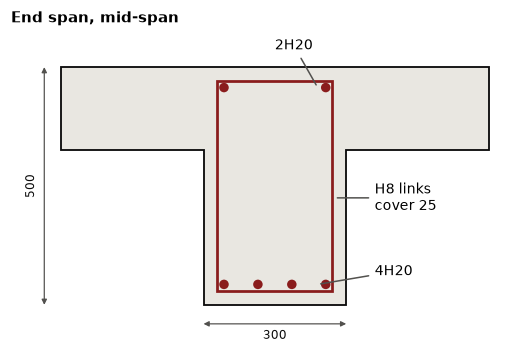

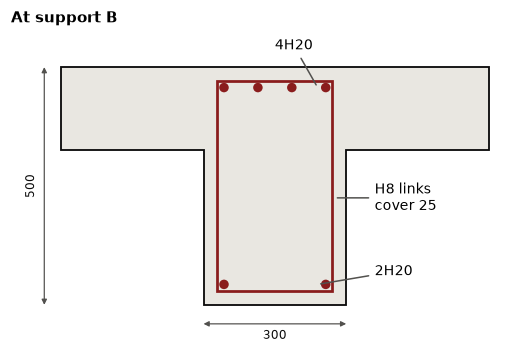

**Beam B schedule (distances from grid 1)**

| Location | Provide |
|:--|:-:|
| Bottom, end spans | 4H20 (2 run full length, 2 from 0.00 m to 5.32 m) |
| Bottom, interior span | 2H20 |
| Top, full length | 2H20 |
| Top, support A | 3H20 |
| Top, support B | 4H20 (extra 2 from 3.99 m to 8.17 m) |
| Links | H8 – 2 legs @ 200 for 1.2 m each side of interior supports, @ 300 elsewhere |


### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| moment distribution agrees with the three-moment equation in every arrangement |  | – | ✅ PASS |
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 Table 5.6 | 0.28 | ✅ PASS |
| fire – side axis distance | EN 1992-1-2 Table 5.6 | 0.28 | ✅ PASS |
| stress block within flange end span | EC2 3.1.7(3) | 0.08 | ✅ PASS |
| singly reinforced end span | EC2 5.5(4) | 0.08 | ✅ PASS |
| area provided bottom, end span | EC2 6.1, 9.2.1.1 | 0.82 | ✅ PASS |
| clear bar spacing bottom, end span | EC2 8.2(2) | 0.49 | ✅ PASS |
| maximum steel bottom, end span | EC2 9.2.1.1(3) | 0.21 | ✅ PASS |
| stress block within flange interior span | EC2 3.1.7(3) | 0.04 | ✅ PASS |
| singly reinforced interior span | EC2 5.5(4) | 0.04 | ✅ PASS |
| area provided bottom, interior span | EC2 6.1, 9.2.1.1 | 0.76 | ✅ PASS |
| clear bar spacing bottom, interior span | EC2 8.2(2) | 0.13 | ✅ PASS |
| maximum steel bottom, interior span | EC2 9.2.1.1(3) | 0.10 | ✅ PASS |
| singly reinforced support B | EC2 5.5(4) | 0.65 | ✅ PASS |
| area provided top, support B | EC2 6.1, 9.2.1.1 | 0.92 | ✅ PASS |
| clear bar spacing top, support B | EC2 8.2(2) | 0.49 | ✅ PASS |
| maximum steel top, support B | EC2 9.2.1.1(3) | 0.21 | ✅ PASS |
| singly reinforced support A | EC2 5.5(4) | 0.31 | ✅ PASS |
| area provided top, support A | EC2 6.1, 9.2.1.1 | 0.55 | ✅ PASS |
| clear bar spacing top, support A | EC2 8.2(2) | 0.29 | ✅ PASS |
| maximum steel top, support A | EC2 9.2.1.1(3) | 0.16 | ✅ PASS |
| strut crushing at face near support B | EC2 6.2.1(8), 6.2.3(3) | 0.28 | ✅ PASS |
| minimum links near support B | EC2 9.2.2(5) | 0.52 | ✅ PASS |
| design links near support B | EC2 6.2.3(3) | 0.79 | ✅ PASS |
| longitudinal link spacing near support B | EC2 9.2.2(6) | 0.58 | ✅ PASS |
| strut crushing at face support A and mid-spans | EC2 6.2.1(8), 6.2.3(3) | 0.18 | ✅ PASS |
| minimum links support A and mid-spans | EC2 9.2.2(5) | 0.78 | ✅ PASS |
| design links support A and mid-spans | EC2 6.2.3(3) | 0.78 | ✅ PASS |
| longitudinal link spacing support A and mid-spans | EC2 9.2.2(6) | 0.88 | ✅ PASS |
| flange struts | EC2 6.2.4(4) | 0.17 | ✅ PASS |
| flange transverse steel | EC2 6.2.4(4), (5) | 0.60 | ✅ PASS |
| deflection (span/depth) | EC2 7.4.2 | 0.25 | ✅ PASS |
| crack control end span | EC2 7.3.3(2) | 0.29 | ✅ PASS |
| minimum steel for cracking end span | EC2 7.3.2 | 0.12 | ✅ PASS |
| crack control support B | EC2 7.3.3(2) | 0.36 | ✅ PASS |
| bent-bar anchorage bottom bars at A | EC2 9.2.1.4(3), 8.4.3(3) | 0.80 | ✅ PASS |
| no mandrel check needed bottom bars at A | EC2 8.3(3) | 0.26 | ✅ PASS |
| bottom steel continued to the end support | EC2 9.2.1.4(1) | 0.50 | ✅ PASS |

**All checks pass.**

In [12]:
P.beam_section(bw, h, c, link, (n_run, phi), (n_AB, phi), "End span, mid-span", hf, beff)
P.beam_section(bw, h, c, link, (n_B, phi), (n_run, phi), "At support B", hf, beff)
table([["Bottom, end spans", f"{n_AB}H{phi} ({n_run} run full length, {n_AB - n_run} from {xs:.2f} m to {xe:.2f} m)"], ["Bottom, interior span", f"{n_BC}H{phi}"], ["Top, full length", f"{n_run}H{phi}"], ["Top, support A", f"{n_A}H{phi}"], ["Top, support B", f"{n_B}H{phi} (extra {n_B - n_run} from {ts:.2f} m to {te:.2f} m)"], ["Links", f"H{link} – {legs} legs @ {s_near} for {zone} m each side of interior supports, @ {s_else} elsewhere"]], ["Location", "Provide"], "Beam B schedule (distances from grid 1)")
s.summary()

**Beam 2** (5 m spans) follows the same steps. Its analysis is below because its reactions load column B2.

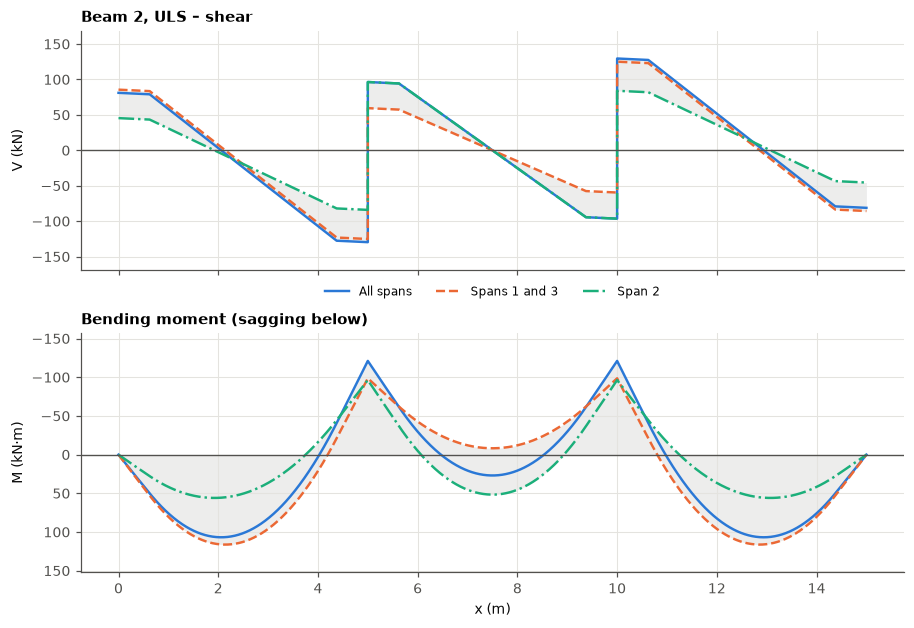

In [13]:
c2 = PJ.design_cases("2"); P.envelope(c2, "Beam 2, ULS");